## CORDIC Testbench


This notebook is to test the implementation of a CORDIC running on the programmable logic. The CORDIC is used to convert cartesian to polar coordinates. The output is compared with a Python calculation of the coordinate transform. It takes in x and y and gives out r and theta where r is the radius and theta is the angle.

In [1]:
from pynq import Overlay
from pynq import MMIO
import numpy as np
import os, struct
import binascii
import cmath
import random
import matplotlib.pyplot as plt
import xml.etree.ElementTree as ET
from types import SimpleNamespace

NUM_SAMPLES = 50

/usr/local/share/pynq-venv/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


In [2]:
# Helper functions
def load_hls_ip(bit_file, ip_name=None, verbose=True):
    """Load an overlay and return everything needed to talk to an HLS IP.

    Returns a namespace with:
      .overlay  the pynq Overlay        .name  IP instance name
      .mmio     MMIO(base, range)       .base / .size  from the .hwh
      .regs     {lowercase register name: offset}   (offsets relative to .base)
    Pass ip_name=... if the overlay has more than one HLS IP.
    """
    ol  = Overlay(bit_file)
    hwh = os.path.splitext(bit_file)[0] + ".hwh"

    if ip_name is None:
        cands = [n for n, d in ol.ip_dict.items() if ":hls:" in str(d.get("type", ""))]
        if len(cands) != 1:
            raise ValueError(f"Pass ip_name=...  HLS candidates: {cands}; "
                             f"all IPs: {list(ol.ip_dict)}")
        ip_name = cands[0]

    d = ol.ip_dict[ip_name]
    base, size = d["phys_addr"], d["addr_range"]

    # register offsets: PYNQ's parsed copy first, raw .hwh as a fallback
    regs = {k.lower(): v["address_offset"] for k, v in (d.get("registers") or {}).items()}
    if not regs:
        for mod in ET.parse(hwh).iter("MODULE"):
            if mod.get("INSTANCE") == ip_name:
                for reg in mod.iter("REGISTER"):
                    props = {p.get("NAME"): p.get("VALUE") for p in reg.iter("PROPERTY")}
                    if props.get("ADDRESS_OFFSET") is not None:
                        regs[reg.get("NAME").lower()] = int(props["ADDRESS_OFFSET"], 0)

    if verbose:
        print(f"{ip_name}: base={base:#x}  range={size:#x} ({size // 1024} KB)")
        for name, off in sorted(regs.items(), key=lambda kv: kv[1]):
            print(f"  {off:#04x}  {name}")

    return SimpleNamespace(overlay=ol, name=ip_name, mmio=MMIO(base, size),
                           base=base, size=size, regs=regs)


def f2w(x):   # python float -> 32-bit IEEE-754 word
    return struct.unpack('<I', struct.pack('<f', x))[0]

def w2f(w):   # 32-bit word -> python float
    return struct.unpack('<f', struct.pack('<I', w & 0xFFFFFFFF))[0]


In [3]:
ip  = load_hls_ip("cordiccart2pol.bit")
OFF = ip.regs

cordiccart2pol_0: base=0x40000000  range=0x10000 (64 KB)
  0x00  ctrl
  0x04  gier
  0x08  ip_ier
  0x0c  ip_isr
  0x10  x
  0x18  y
  0x20  r
  0x24  r_ctrl
  0x30  theta
  0x34  theta_ctrl


In [4]:
r_error=np.zeros(NUM_SAMPLES)
theta_error=np.zeros(NUM_SAMPLES)
ind=np.arange(NUM_SAMPLES)
r_rmse=np.zeros(NUM_SAMPLES)
theta_rmse=np.zeros(NUM_SAMPLES)

In [5]:
for i in range(NUM_SAMPLES):
    x = random.uniform(-1, 1)
    y = random.uniform(-1, 1)

    cn = cmath.polar(complex(x, y))

    ip.mmio.write(OFF['x'], f2w(x))
    ip.mmio.write(OFF['y'], f2w(y))

    ip.mmio.write(OFF['ctrl'], 1)      # ap_start (same start/stop writes as before)
    ip.mmio.write(OFF['ctrl'], 0)

    r = w2f(ip.mmio.read(OFF['r']))
    theta = w2f(ip.mmio.read(OFF['theta']))

    r_error[i]     = abs(r - cn[0])
    theta_error[i] = abs(theta - cn[1])

## Verifying Functionality

In [6]:
sum_sq_r=0
sum_sq_theta=0
for i in range(NUM_SAMPLES):
    sum_sq_r =sum_sq_r+(r_error[i]*r_error[i])
    r_rmse = np.sqrt(sum_sq_r / (i+1))
    sum_sq_theta =sum_sq_theta+(theta_error[i]*theta_error[i])
    theta_rmse = np.sqrt(sum_sq_theta / (i+1))
print("Radius RMSE: ", r_rmse, "Theta RMSE:", theta_rmse)    
if r_rmse<0.001 and theta_rmse<0.001:
    print("PASS")
else:
    print("FAIL")

Radius RMSE:  2.565543588151379e-08 Theta RMSE: 1.7381571191376148e-05
PASS


## Displaying Errors

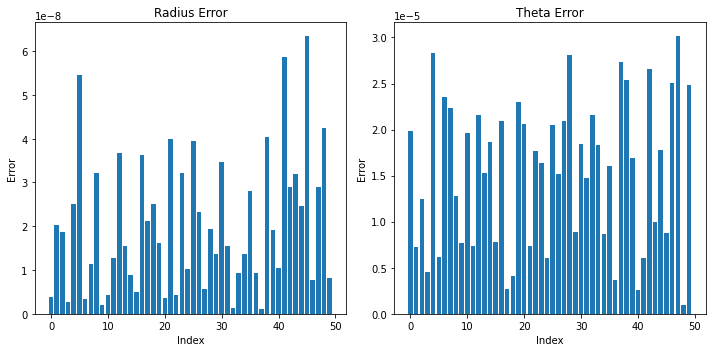

In [7]:
plt.figure(figsize=(10, 5))
plt.subplot(1,2,1)
plt.bar(ind,r_error)
plt.title("Radius Error")
plt.xlabel("Index")
plt.ylabel("Error")
#plt.xticks(ind)
plt.tight_layout()

plt.subplot(1,2,2)
plt.bar(ind,theta_error)
plt.title("Theta Error")
plt.xlabel("Index")
plt.ylabel("Error")
#plt.xticks(ind)
plt.tight_layout()